## Motivação  

Boa parte dos dados do mundo chega sem resposta nenhuma. Esta aula trabalha com uma tabela assim: 1.095 tumores de mama, cada um descrito pela expressão de 505 genes, e nenhuma coluna de rótulo. Tratamos os genes como atributos numéricos quaisquer, quase anônimos. 

A pergunta é se os próprios dados se organizam em grupos e, se sim, como dar nome a esses grupos e transformá-los em rótulos para treinar um classificador.

## Objetivos  

- Explicar por que a escala dos atributos muda o resultado da PCA e do K-means e padronizá-los com o StandardScaler.  
- Reduzir a dimensionalidade com PCA para modelagem e com UMAP para visualização, justificando o papel de cada um.  
- Agrupar amostras com K-means e escolher o número de grupos com inércia e silhueta.  
- Dar nome aos grupos com atributos discriminantes, um dicionário de assinaturas e uma árvore de decisão substituta.  
- Filtrar rótulos pela margem de distância aos centroides e usá-los para treinar um classificador supervisionado (pseudo-labeling).  
- Comparar uma partição encontrada sem rótulos com uma classificação de referência pelo índice de Rand ajustado.

## Preparando os dados

In [2]:
# Importa as bibliotecas e define o tema dos gráficos
import json

import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import f_classif
from sklearn.metrics import (
    adjusted_rand_score,
    pairwise_distances,
    silhouette_score,
)
from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_score,
)
from sklearn.preprocessing import StandardScaler
from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree,
)

from umap import UMAP

sns.set_theme(style="whitegrid", palette="colorblind")

c:\Users\morae\Documentos - Armazenamento_Local\TI_IMD\DISCIPLINAS\Ciencia de Dados\data-science\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm



Como usar este roteiro
A base está em tcga-brca/data/, em três arquivos: a matriz de expressão brca_hvgs_log2.parquet, o dicionário dicionario_marcadores.json e a classificação oficial brca_pam50.csv, que só aparece na última seção. Para ler o Parquet e rodar o UMAP, instale, se ainda não tiver, pip install pyarrow umap-learn. A matriz já vem pré-processada; o script tcga-brca/preparar_dados.py mostra como ela foi gerada, mas não precisa ser executado.

In [3]:
# Carrega a matriz de expressão: pacientes nas linhas, genes nas colunas
expressao_genica = pd.read_parquet("../../data/brca_hvgs_log2.parquet")

expressao_genica.iloc[:5, :8]

,SCGB2A2,SCGB1D2,TFF1,PIP,CPB1,CLEC3A,S100A7,AGR3
paciente,,,,,,,,
TCGA-3C-AAAU,13.128,11.093,5.102,11.536,11.350,0.487,0.000,9.651
TCGA-3C-AALI,13.079,9.195,6.100,6.711,0.833,7.816,0.642,9.822
TCGA-3C-AALJ,0.000,0.935,6.239,0.000,5.978,0.000,0.362,8.771
TCGA-3C-AALK,5.586,5.102,12.045,9.772,2.190,2.249,4.635,7.498
TCGA-4H-AAAK,12.143,8.230,11.101,6.135,0.597,3.853,0.427,7.899


In [4]:
# Verificações de qualidade: ausentes, repetidos, constantes e faixa de valores
quality_checks = pd.Series(
    {
        "valores ausentes": expressao_genica.isna().sum().sum(),
        "pacientes repetidos": expressao_genica.index.duplicated().sum(),
        "genes constantes": (expressao_genica.var() == 0).sum(),
        "menor valor": expressao_genica.min().min(),
        "maior valor": expressao_genica.max().max(),
    },
    name="resultado",
    dtype="object",
)

quality_checks

valores ausentes            0
pacientes repetidos         0
genes constantes            0
menor valor               0.0
maior valor            17.931
Name: resultado, dtype: object

In [5]:
# Dicionário de assinaturas: perfil -> genes marcadores
with open("../../data/dicionario_marcadores.json") as file:
    markers = json.load(file)

markers_table = (
    pd.Series(markers)
    .map(", ".join)
    .rename_axis("perfil")
    .rename("genes")
    .to_frame()
)

markers_table

,genes
perfil,
Hormonal,"ESR1, PGR, GATA3, FOXA1"
HER2,"ERBB2, GRB7"
Basal,"KRT5, KRT16, FOXC1, EGFR"
Proliferativo,"MKI67, AURKA"
Estromal,"COL14A1, C7, ADH1B"


## Roteiro:

1. Inspeção estrutural da base;
2. Padronização de Escala;
3. Redução de Dimensionalidade;
4. Particionar as amostras em torno de centroides;
5. Rotulagem e Classificação;
6. Validação Externa.

### 2. Padronização de Escala

In [22]:
# Média e desvio-padrão de cada gene, resumidos sobre os 505 genes

estatisticas_genes = (
    expressao_genica
    .agg(["mean", "std"])
    .T
)

estatisticas_genes_resumo = estatisticas_genes.describe().round(2)

estatisticas_genes_resumo

,mean,std
count,505.00,505.00
mean,3.69,2.10
std,1.75,0.43
min,1.01,1.14
25%,2.38,1.80
50%,3.31,1.97
75%,4.73,2.28
max,10.09,4.49


- Visualização

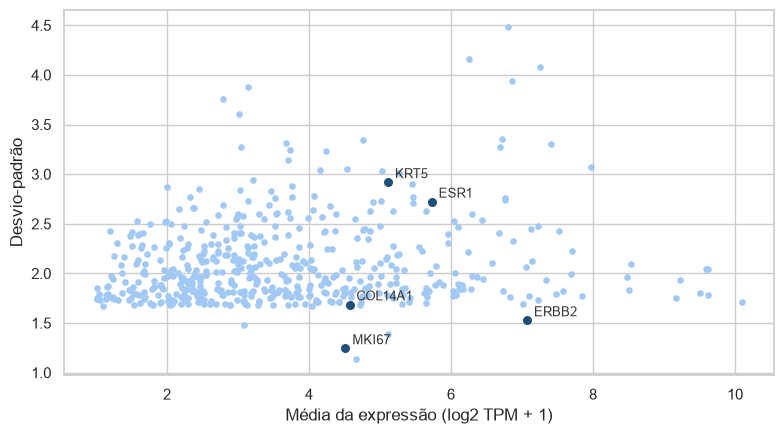

In [23]:
# Média versus desvio-padrão de cada gene, com alguns marcadores em destaque
highlight = ["ESR1", "KRT5", "ERBB2", "MKI67", "COL14A1"]

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(estatisticas_genes["mean"], estatisticas_genes["std"], color="#A1C9F4", s=14)
ax.scatter(estatisticas_genes.loc[highlight, "mean"], estatisticas_genes.loc[highlight, "std"],
           color="#1F4E79", s=30)
           
for gene in highlight:
    ax.annotate(gene, estatisticas_genes.loc[gene, ["mean", "std"]], xytext=(5, 3),
                textcoords="offset points", fontsize=9, color="#333333")
ax.set(xlabel="Média da expressão (log2 TPM + 1)", ylabel="Desvio-padrão")
plt.tight_layout()
plt.show()

- Aplicaçao do StandardScaler sobre a matriz de expressão para transformar cada coluna em escore-z ($\text{média} = 0$ e $\text{desvio-padrão} = 1$).

In [24]:
# Padroniza cada gene para média 0 e desvio-padrão 1

scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(expressao_genica),
    index=expressao_genica.index,
    columns=expressao_genica.columns,
)

scaled_check = (
    X_scaled
    .agg(["mean", "std"])
    .T
    .describe()
    .loc[["min", "max"]]
    .round(3)
)

scaled_check

,mean,std
min,-0.0,1.0
max,0.0,1.0


A variável X_scaled guarda os novos valores escalonados/padronizados.

In [25]:
X_scaled.iloc[:5, :8]

,SCGB2A2,SCGB1D2,TFF1,PIP,CPB1,CLEC3A,S100A7,AGR3
paciente,,,,,,,,
TCGA-3C-AAAU,1.409471,1.163917,-0.526073,1.187780,2.117048,-0.614416,-0.835666,0.874126
TCGA-3C-AALI,1.398545,0.706935,-0.281548,-0.038825,-0.595036,1.338707,-0.657617,0.925129
TCGA-3C-AALJ,-1.517934,-1.281828,-0.247491,-1.744886,0.731737,-0.744197,-0.735271,0.611652
TCGA-3C-AALK,-0.272315,-0.278538,1.175066,0.739338,-0.245098,-0.144856,0.449779,0.231961
TCGA-4H-AAAK,1.189827,0.474591,0.943772,-0.185255,-0.655894,0.282598,-0.717244,0.351565


- Efeito da padronização no PCA:

In [27]:
# PC1 com e sem padronização: variância explicada e genes de maior peso
pca_by_input = {
    name: PCA(n_components=15, random_state=42).fit(data)
    for name, data in {"sem padronizar": expressao_genica, "padronizado": X_scaled}.items()
}

pc1_comparison = pd.DataFrame(
    {
        name: {
            "variância da PC1": f"{model.explained_variance_ratio_[0]:.1%}",
            "genes de maior peso": ", ".join(
                pd.Series(np.abs(model.components_[0]), index=expressao_genica.columns)
                .nlargest(5)
                .index
            ),
        }
        for name, model in pca_by_input.items()
    }
).T

pc1_comparison

,variância da PC1,genes de maior peso
sem padronizar,20.3%,"TFF1, AGR3, TFF3, AGR2, ESR1"
padronizado,19.4%,"FOXA1, MLPH, ESR1, TBC1D9, AGR3"


Para cada versão, listamos a variância que ela explica e os cinco genes com maior peso (loading) em valor absoluto.  
Sem padronizar, a PC1 explica 20,3% da variância e tem como genes de maior peso TFF1, AGR3 e TFF3, justamente alguns dos genes de maior desvio-padrão. Padronizada, explica 19,4% e passa a ser liderada por FOXA1, MLPH e ESR1, genes que variam juntos com muitos outros. A direção principal mudou pouco, porque os dois trios de genes acompanham o mesmo eixo de variação, mas a ordem de importância deixou de premiar quem tem a escala maior.

Neste conjunto, o efeito é modesto porque a seleção dos HVGs já deixou de fora os genes de variância muito pequena. Em dados tabulares comuns, com atributos em reais, anos e porcentagens, a diferença costuma ser drástica. A regra prática vale nos dois casos: antes de qualquer método baseado em distância ou variância, padronize.

### 3. Redução de Dimensionalidade

#### PCA

In [ ]:
# Aplicação do PCA completo

pca_full = PCA(random_state=42).fit(X_scaled)


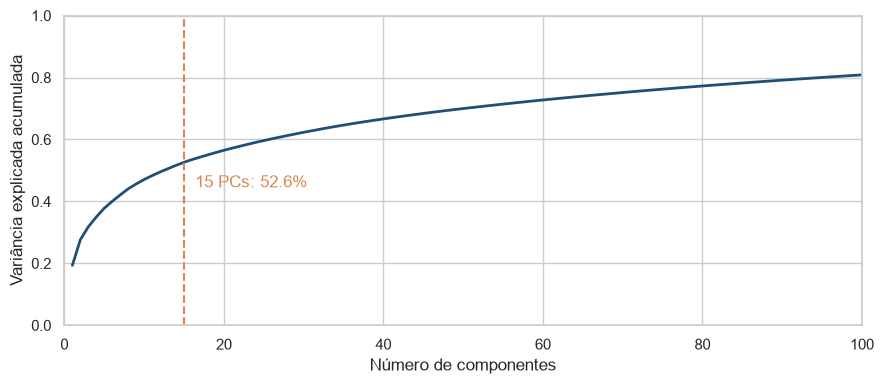

In [29]:

# Variância explicada acumulada por todas as componentes e representação gráfica.
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)


fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, 101), cumulative_variance[:100], color="#1F4E79", linewidth=2)
ax.axvline(15, color="#DD8452", linestyle="--")
ax.annotate(f"15 PCs: {cumulative_variance[14]:.1%}", (15, cumulative_variance[14]),
            xytext=(8, -18), textcoords="offset points", color="#DD8452")
ax.set(xlabel="Número de componentes", ylabel="Variância explicada acumulada",
       xlim=(0, 100), ylim=(0, 1))
plt.tight_layout()
plt.show()

A curva sobe rápido nas primeiras componentes e depois se arrasta. As 15 primeiras explicam 52,6% da variância, e seriam necessárias 95 para chegar a 80%. Ficamos com 15: elas guardam a estrutura de grande escala, compartilhada por muitos genes, e deixam de fora uma longa cauda de componentes que capturam, cada uma, menos de 1% da variância e são em boa parte ruído.

In [30]:
# Projeta os pacientes nas 15 primeiras componentes principais

pca = PCA(n_components=15, random_state=42)
X_pca = pca.fit_transform(X_scaled)

X_pca.shape

(1095, 15)

#### UMAP

Quinze dimensões ainda não cabem em um gráfico. Poderíamos plotar só a PC1 contra a PC2, mas elas resumem pouco mais de um quarto da variância. O UMAP (Uniform Manifold Approximation and Projection) é um método não linear que constrói um grafo de vizinhos no espaço original e procura uma disposição em 2D que preserve esses vizinhos. Aplicamos o UMAP às 15 componentes:

In [ ]:
# Aplicação do UMAP para projeta as 15 componentes em 2D com o UMAP, apenas para visualização

umap_model = UMAP(n_neighbors=15, min_dist=0.1, random_state=42)

embedding = pd.DataFrame(
    umap_model.fit_transform(X_pca),
    index=expressao_genica.index,
    columns=["UMAP1", "UMAP2"],
)

embedding.head()

c:\Users\morae\Documentos - Armazenamento_Local\TI_IMD\DISCIPLINAS\Ciencia de Dados\data-science\.venv\Lib\site-packages\umap\umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
c:\Users\morae\Documentos - Armazenamento_Local\TI_IMD\DISCIPLINAS\Ciencia de Dados\data-science\.venv\Lib\site-packages\umap\umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


,UMAP1,UMAP2
paciente,,
TCGA-3C-AAAU,12.342524,8.750246
TCGA-3C-AALI,8.595473,5.546235
TCGA-3C-AALJ,11.869732,7.322466
TCGA-3C-AALK,7.670802,9.700511
TCGA-4H-AAAK,7.549385,9.579863


- Representação grafica do UMAP

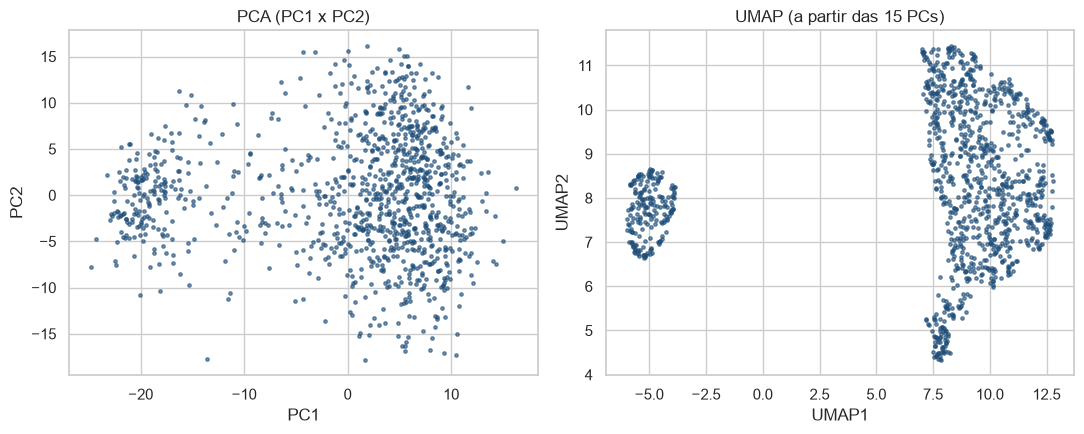

In [33]:
# Os mesmos pacientes no plano PC1 x PC2 e no plano do UMAP

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], color="#1F4E79", s=6, alpha=0.6)
axes[0].set(title="PCA (PC1 x PC2)", xlabel="PC1", ylabel="PC2")
axes[1].scatter(embedding["UMAP1"], embedding["UMAP2"], color="#1F4E79", s=6, alpha=0.6)
axes[1].set(title="UMAP (a partir das 15 PCs)", xlabel="UMAP1", ylabel="UMAP2")
plt.tight_layout()
plt.show()

No plano PC1 x PC2 já se vê um grupo separado à esquerda e uma nuvem maior à direita. O UMAP deixa essa separação mais nítida e sugere subdivisões dentro da nuvem.

O UMAP preserva quem é vizinho de quem, mas distorce o tamanho aparente de um grupo e a distância entre dois grupos no gráfico não têm significado quantitativo.  
Por isso, a divisão de trabalho desta aula é rígida. A PCA é o espaço de trabalho, onde se calculam distâncias e se ajusta o K-means. O UMAP é só a tela onde desenhamos os resultados.

### 4. Particionar as amostras em torno de centroides: Agrupamento com K-means

- Escolha do valor k

In [34]:
# Inércia e silhueta para k de 2 a 8, no espaço das 15 componentes
k_values = range(2, 9)

kmeans_by_k = {
    k: KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_pca)
    for k in k_values
}

k_selection = pd.DataFrame(
    {
        "inércia": [model.inertia_ for model in kmeans_by_k.values()],
        "silhueta": [
            silhouette_score(X_pca, model.labels_) for model in kmeans_by_k.values()
        ],
    },
    index=pd.Index(k_values, name="k"),
).round(3)

k_selection

,inércia,silhueta
k,,
2,202505.296,0.334
3,174539.570,0.199
4,156028.057,0.203
5,146527.963,0.172
6,139424.099,0.172
7,134707.780,0.162
8,130832.737,0.155


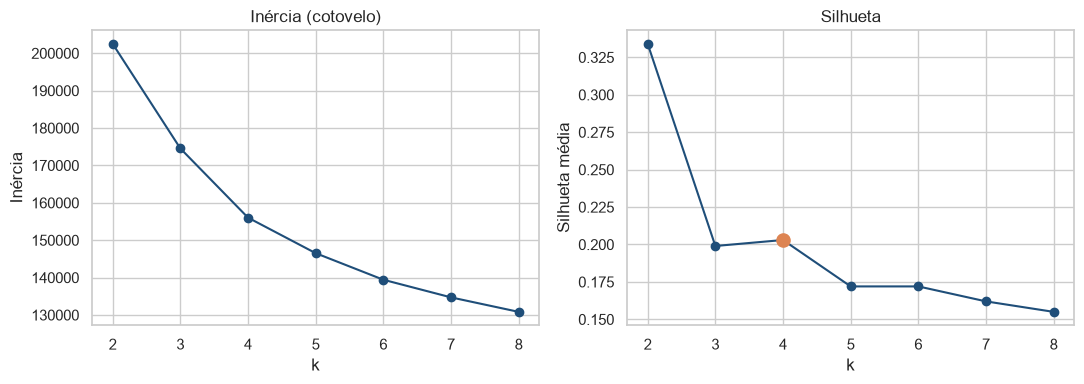

In [ ]:
# Curvas de inércia e silhueta em função de k

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(k_selection.index, k_selection["inércia"], marker="o", color="#1F4E79")
axes[0].set(xlabel="k", ylabel="Inércia", title="Inércia (cotovelo)")

axes[1].plot(k_selection.index, k_selection["silhueta"], marker="o", color="#1F4E79")
axes[1].scatter(4, k_selection.loc[4, "silhueta"], color="#DD8452", s=90, zorder=3)
axes[1].set(xlabel="k", ylabel="Silhueta média", title="Silhueta")

plt.tight_layout()
plt.show()

Ficamos com k=4, ultimo ponto de redução significativa de inércia.

- Aplicação do k-means

In [ ]:
# K-means com k = 4 e o tamanho de cada grupo
kmeans = KMeans(n_clusters=4, n_init=10, random_state=42).fit(X_pca)

clusters = pd.Series(kmeans.labels_, index=expressao_genica.index, name="cluster")

cluster_sizes = clusters.value_counts().sort_index()

cluster_sizes

cluster
0    181
1    374
2    346
3    194
Name: count, dtype: int64

Os quatro grupos têm 181, 374, 346 e 194 pacientes.  
Os indices são apenas identificadores, sem ordem nem significado.

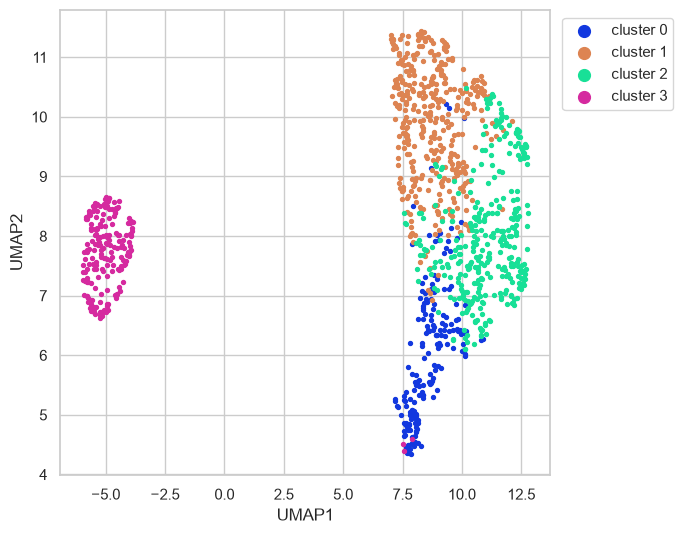

In [38]:
# Representação grafica dos clusters com UMAP colorido pelo identificador bruto do cluster

cluster_colors = {0: "#1238DF", 1: "#DD8452", 2: "#18E097", 3: "#D52A9F"}

fig, ax = plt.subplots(figsize=(7, 5.5))
for cluster_id, color in cluster_colors.items():
    members = embedding[clusters == cluster_id]
    ax.scatter(members["UMAP1"], members["UMAP2"], color=color, s=8,
               label=f"cluster {cluster_id}")
ax.set(xlabel="UMAP1", ylabel="UMAP2")
ax.legend(markerscale=3, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

Os grupos foram calculados nas 15 componentes, sem nenhuma informação do UMAP, e mesmo assim ocupam regiões contíguas no gráfico. O cluster isolado à esquerda corresponde ao grupo que a silhueta já separava em k=2. Os outros três dividem a nuvem maior, com fronteiras que se tocam.

### 5. Rotulagem e Classificação

- Agora precisamos descobrir o que cada um representa.  Um cluster é só uma lista de pacientes. Para torná-lo útil, precisamos saber o que o distingue dos demais.

#### 5.1 Atributos discriminantes

In [39]:
# Escore-z médio de cada gene dentro de cada cluster

cluster_zscores = X_scaled.groupby(clusters).mean()

top_genes = pd.DataFrame(
    {
        f"cluster {cluster_id}": row.nlargest(5).index
        for cluster_id, row in cluster_zscores.iterrows()
    },
    index=pd.RangeIndex(1, 6, name="posição"),
)

top_genes

,cluster 0,cluster 1,cluster 2,cluster 3
posição,,,,
1,MAB21L4,COL14A1,NKAIN1,FOXC1
2,SPINK8,MFAP4,ESR1,VGLL1
3,CLCA2,C7,KCNJ3,EN1
4,ABCA12,COL17A1,SLC39A6,PPP1R14C
5,ERBB2,OGN,TPSP2,KRT16


In [40]:
# Estatística F e p-valor da ANOVA de cada gene, com os clusters como grupos

f_statistic, p_values = f_classif(expressao_genica, clusters)
f_scores = pd.Series(f_statistic, index=expressao_genica.columns, name="F")

anova_ranking = (
    f_scores
    .nlargest(10)
    .round(0)
    .to_frame()
)

anova_ranking

,F
FOXA1,2229.0
MLPH,1521.0
SPDEF,1079.0
FOXC1,1034.0
ESR1,949.0
AGR3,909.0
PRR15,852.0
TBC1D9,846.0
AGR2,826.0
GATA3,808.0


#### 5.2 Tradução pelo dicionário

Com os genes de cada cluster em mãos, entra o dicionário. Em vez de procurar os marcadores um a um nas listas de cinco, calculamos para cada cluster um escore de assinatura: a média dos escores-z médios dos genes de cada perfil. Assim, todo o dicionário é comparado com todos os clusters de uma vez:

In [42]:
# Escore de assinatura: média do escore-z dos genes de cada perfil, por cluster

escore_assinatura = pd.DataFrame(
    {profile: cluster_zscores[genes].mean(axis=1) for profile, genes in markers.items()}
).rename_axis("cluster")

escore_assinatura.round(2)

,Hormonal,HER2,Basal,Proliferativo,Estromal
cluster,,,,,
0,-0.29,0.81,-0.29,0.33,-0.37
1,0.45,-0.00,0.17,-0.61,0.83
2,0.56,-0.10,-0.74,0.08,-0.42
3,-1.60,-0.58,1.27,0.72,-0.51


In [43]:
# Rótulo de cada cluster: o perfil de maior escore de assinatura

cluster_names = escore_assinatura.idxmax(axis=1)
labels = clusters.map(cluster_names).rename("rotulo")

label_sizes = labels.value_counts()

label_sizes

rotulo
Estromal    374
Hormonal    346
Basal       194
HER2        181
Name: count, dtype: int64

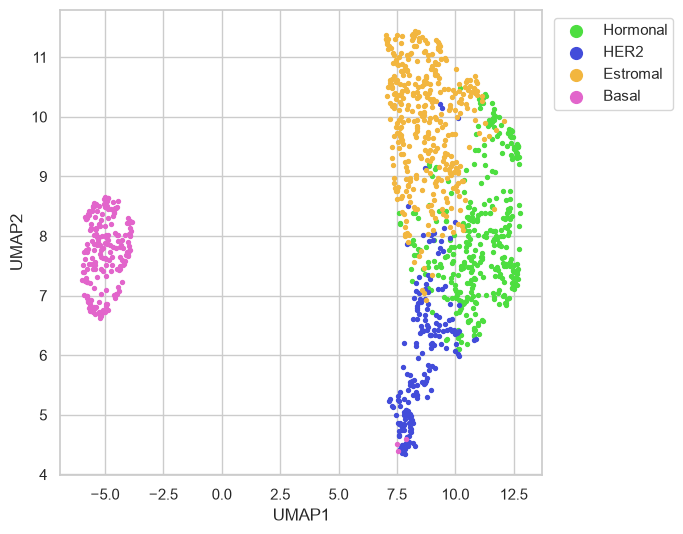

In [45]:
# UMAP com rótulos

label_colors = {
    "Hormonal": "#4DDE40",
    "HER2": "#424CDA",
    "Estromal": "#F2B63F",
    "Basal": "#E265CB",
}

fig, ax = plt.subplots(figsize=(7, 5.5))
for label, color in label_colors.items():
    members = embedding[labels == label]
    ax.scatter(members["UMAP1"], members["UMAP2"], color=color, s=8, label=label)
ax.set(xlabel="UMAP1", ylabel="UMAP2")
ax.legend(markerscale=3, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

5.3 Árvore de decisão substituta (Ferramenta de interpretabilidade)

Treinamos uma árvore de decisão rasa para prever o rótulo de cada paciente a partir da expressão original dos 505 genes. A árvore não tem a pretensão de prever pacientes novos. Ela é um modelo substituto (surrogate model): um modelo simples, que imita o K-means e cujas regras podemos ler.

In [46]:
# Árvore de decisão de profundidade 3 imitando a partição do K-means

arvore_substituta = DecisionTreeClassifier(max_depth=3, random_state=42).fit(expressao_genica, labels)
fidelity = arvore_substituta.score(expressao_genica, labels)

round(fidelity, 3)

0.829

Aqui, .score é medido nos mesmos dados do ajuste, de propósito. Ele mede a fidelidade da árvore ao K-means, ou seja, quanto ela consegue reproduzir a partição, e não a capacidade de generalizar.

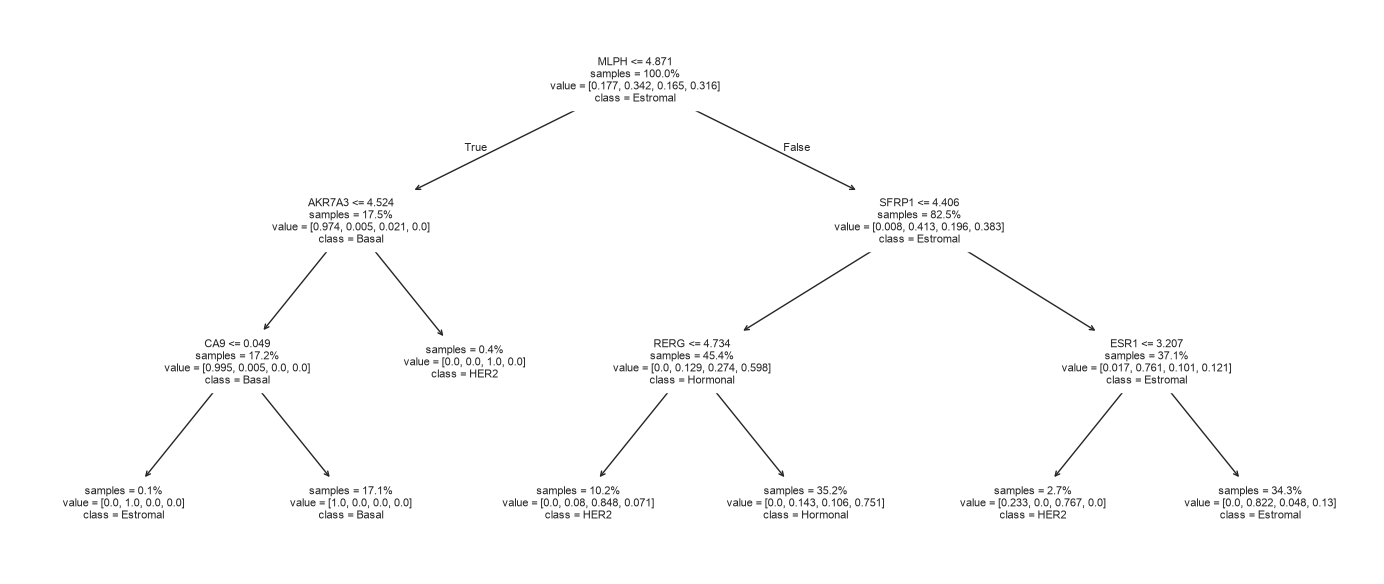

In [48]:
# Regras da árvore substituta

fig, ax = plt.subplots(figsize=(14, 6))
plot_tree(arvore_substituta, feature_names=expressao_genica.columns, class_names=arvore_substituta.classes_,
          filled=False, impurity=False, proportion=True, fontsize=8, ax=ax)
plt.tight_layout()
plt.show()

Com só três perguntas por paciente, a árvore reproduz o rótulo do K-means em 82,9% dos casos. Ela escolheu os genes sozinha, e quase nenhum deles está no dicionário. A primeira pergunta é MLPH <= 4.871. MLPH é o segundo gene do ranking da ANOVA, e o ramo de expressão baixa reúne 17,5% dos pacientes, 97,4% deles do grupo Basal. No ramo de expressão alta, SFRP1 separa o Estromal, com valores altos, do Hormonal e do HER2, e RERG separa esses dois. O próprio ESR1 aparece no último nível, retirando do ramo Estromal um pequeno grupo de tumores HER2.

As regras dão uma descrição alternativa de cada grupo: o cluster Hormonal, por exemplo, é “MLPH alto, SFRP1 baixo e RERG alto”. Uma árvore mais profunda seria mais fiel e mais difícil de ler. A profundidade 3 é um compromisso entre fidelidade e legibilidade.

### 6. Classificador e validação

 O K-means é categórico: um paciente exatamente na fronteira entre dois centroides recebe um rótulo com a mesma convicção de um paciente no centro do grupo. Se treinarmos com rótulos duvidosos, o classificador aprende fronteiras igualmente duvidosas.

6.1 Uma margem de confiança

In [50]:
# Razão entre a distância ao centroide mais próximo e ao segundo mais próximo

centroid_distances = np.sort(kmeans.transform(X_pca), axis=1)
distance_ratio = pd.Series(
    centroid_distances[:, 0] / centroid_distances[:, 1],
    index=expressao_genica.index,
    name="razao",
)
confident = distance_ratio < 0.75

confident.value_counts()

razao
True     642
False    453
Name: count, dtype: int64

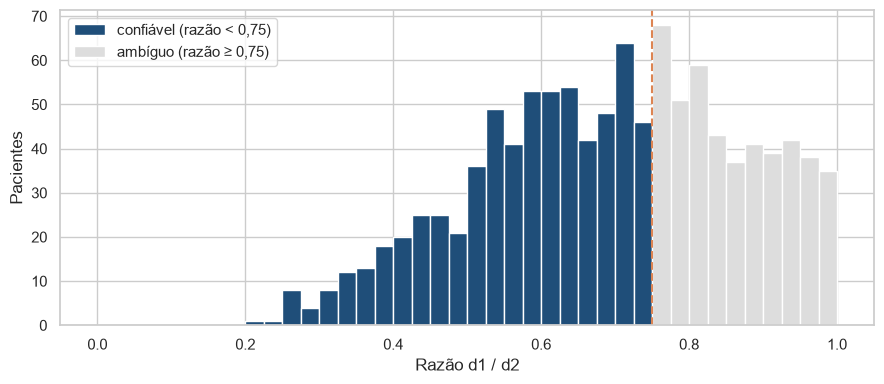

In [51]:
# Distribuição da razão de distâncias, com o corte de 0,75
fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(distance_ratio[confident], bins=np.arange(0, 1.02, 0.025), color="#1F4E79",
        label="confiável (razão < 0,75)")
ax.hist(distance_ratio[~confident], bins=np.arange(0, 1.02, 0.025), color="#DDDDDD",
        label="ambíguo (razão ≥ 0,75)")
ax.axvline(0.75, color="#DD8452", linestyle="--")
ax.set(xlabel="Razão d1 / d2", ylabel="Pacientes")
ax.legend()
plt.tight_layout()
plt.show()

In [52]:
# Pacientes confiáveis e ambíguos em cada rótulo

confidence_by_label = (
    pd.crosstab(labels, confident.map({True: "confiável", False: "ambíguo"}))
    .assign(
        fracao_confiavel=lambda df: (df["confiável"] / df.sum(axis=1)).round(2)
    )
)

confidence_by_label

razao,ambíguo,confiável,fracao_confiavel
rotulo,,,
Basal,9,185,0.95
Estromal,166,208,0.56
HER2,96,85,0.47
Hormonal,182,164,0.47


### 6.2 Treinando o classificador (casos fáceis)

In [53]:
# Validação cruzada da floresta aleatória nos pacientes confiáveis
X_confident = expressao_genica[confident]
y_confident = labels[confident]

forest = RandomForestClassifier(n_estimators=500, random_state=42)
skfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_accuracy = cross_val_score(forest, X_confident, y_confident, cv=skfold,
                              scoring="accuracy")

cv_accuracy.round(3)

array([1.   , 0.984, 0.984, 1.   , 0.977])

A acurácia média é de 98,9%. 
Os pacientes confiáveis foram escolhidos justamente por estarem longe das fronteiras, e as fronteiras são onde um classificador erra.  
Os rótulos também vieram dos mesmos genes que agora servem de atributos. A validação cruzada confirma que a floresta reproduz o K-means nos casos fáceis.

### 6.3 Prevendo os pacientes ambíguos

In [54]:
# Ajuste final nos confiáveis e previsão dos ambíguos

forest.fit(X_confident, y_confident)
X_ambiguous = expressao_genica[~confident]

ambiguous_predictions = pd.DataFrame(
    {
        "kmeans": labels[~confident],
        "floresta": forest.predict(X_ambiguous),
        "probabilidade": forest.predict_proba(X_ambiguous).max(axis=1),
    },
    index=X_ambiguous.index,
)

ambiguous_predictions.head()

,kmeans,floresta,probabilidade
paciente,,,
TCGA-5L-AAT1,Estromal,Estromal,0.738
TCGA-A1-A0SG,Estromal,Estromal,0.492
TCGA-A1-A0SH,Estromal,Estromal,0.584
TCGA-A1-A0SI,HER2,Estromal,0.488
TCGA-A1-A0SJ,Estromal,Estromal,0.654


In [55]:
# Concordância com o K-means e resumo das probabilidades nos ambíguos

agreement = ambiguous_predictions["kmeans"] == ambiguous_predictions["floresta"]
probabilities = ambiguous_predictions["probabilidade"]

ambiguous_summary = pd.Series(
    {
        "concordância com o K-means": agreement.mean(),
        "probabilidade mediana": probabilities.median(),
        "fração com probabilidade < 0,5": (probabilities < 0.5).mean(),
    }
).round(3)

ambiguous_summary

concordância com o K-means        0.770
probabilidade mediana             0.600
fração com probabilidade < 0,5    0.265
dtype: float64

Nos 453 pacientes ambíguos, a floresta concorda com o K-means em 77,0% dos casos. Nos outros 23,0%, ela discorda, e isso não é necessariamente um erro: o K-means decide pela distância nas 15 componentes, enquanto a floresta aprendeu regras nos 505 genes a partir dos casos típicos de cada grupo. A probabilidade mediana é de 0,60, e em 26,5% dos ambíguos nenhuma classe recebe metade dos votos. O classificador não esconde a dúvida. Em um paciente ambíguo, uma probabilidade de 0,45 para HER2 e 0,40 para Hormonal informa mais que um rótulo seco

In [57]:
# Rótulo final e opacidade de cada paciente

final_labels = labels.where(confident, ambiguous_predictions["floresta"])
point_alpha = (
    pd.Series(1.0, index=expressao_genica.index)
    .where(confident, ambiguous_predictions["probabilidade"])
)

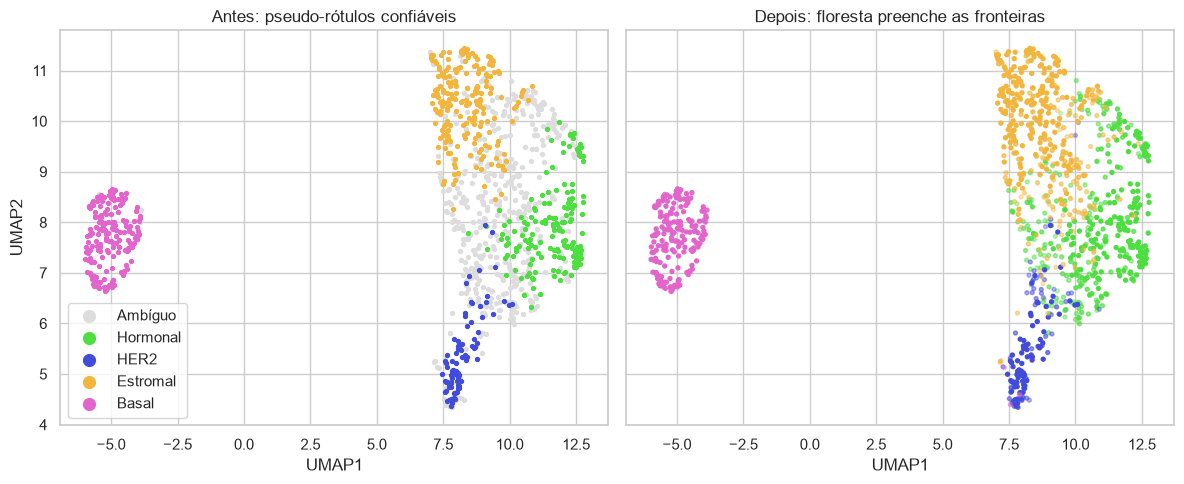

In [58]:
# UMAP antes (clusters com ambíguos em cinza) e depois (previsões da floresta)

label_colors = {
    "Hormonal": "#4DDE40",
    "HER2": "#424CDA",
    "Estromal": "#F2B63F",
    "Basal": "#E265CB",
}

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
ambiguous_points = embedding[~confident]
axes[0].scatter(ambiguous_points["UMAP1"], ambiguous_points["UMAP2"],
                color="#DDDDDD", s=8, label="Ambíguo")
for label, color in label_colors.items():
    members = embedding[confident & (labels == label)]
    axes[0].scatter(members["UMAP1"], members["UMAP2"], color=color, s=8, label=label)
    predicted = final_labels == label
    axes[1].scatter(embedding.loc[predicted, "UMAP1"], embedding.loc[predicted, "UMAP2"],
                    color=color, s=8, alpha=point_alpha[predicted], label=label)
axes[0].set(title="Antes: pseudo-rótulos confiáveis", xlabel="UMAP1", ylabel="UMAP2")
axes[1].set(title="Depois: floresta preenche as fronteiras", xlabel="UMAP1")
axes[0].legend(markerscale=3, loc="lower left")
plt.tight_layout()
plt.show()

### 7. Validação Externa.

In [59]:
# Classificação PAM50 oficial, disponível para parte dos pacientes

pam50 = (
    pd.read_csv("../../data/brca_pam50.csv", index_col="paciente")["pam50"]
    .dropna()
)

pam50_comparison = pd.crosstab(final_labels.loc[pam50.index], pam50)

pam50_comparison

pam50,Basal,Her2,LumA,LumB,Normal
rotulo,,,,,
Basal,135,1,0,0,5
Estromal,1,1,240,16,14
HER2,3,62,13,26,3
Hormonal,0,3,168,150,1


In [60]:
# Índice de Rand ajustado entre a partição final e o PAM50

ari = adjusted_rand_score(pam50, final_labels.loc[pam50.index])

round(ari, 3)

0.399